# Riesgo de impago: Give Me Some Credit

Objetivo: predecir si un cliente tendrá una mora grave (90 días o más) en los próximos 2 años (`SeriousDlqin2yrs`).

Pasos: 1) librerías, 2) análisis exploratorio, 3) regresión logística con grilla, 4) XGBoost con grilla e importancia de variables, 5) conclusiones.

Datos: `cs-training.csv` de la competencia de Kaggle *Give Me Some Credit* (150.000 clientes). Colócalo en `data/`.

## 1. Librerías

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

SEMILLA = 42
pd.set_option("display.width", 160)

## 2. Análisis exploratorio

In [2]:
df = pd.read_csv("../data/cs-training.csv", index_col=0)
df.columns = ["mora", "uso_credito", "edad", "atraso_30_59", "ratio_deuda", "ingreso_mensual",
              "lineas_credito", "atraso_90", "creditos_hipot", "atraso_60_89", "dependientes"]
print(df.shape)
df.head()

(150000, 11)


,mora,uso_credito,edad,atraso_30_59,ratio_deuda,ingreso_mensual,lineas_credito,atraso_90,creditos_hipot,atraso_60_89,dependientes
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
print("Filas duplicadas:", df.duplicated().sum())
print("\nValores vacíos:")
print(df.isna().sum().to_frame("vacios").assign(pct=lambda x: (x.vacios/len(df)*100).round(1)))
print("\nBalance de la variable objetivo:")
print(df["mora"].value_counts().to_frame("clientes").assign(pct=lambda x: (x.clientes/len(df)*100).round(2)))

Filas duplicadas: 609

Valores vacíos:
                 vacios   pct
mora                  0   0.0
uso_credito           0   0.0
edad                  0   0.0
atraso_30_59          0   0.0
ratio_deuda           0   0.0
ingreso_mensual   29731  19.8
lineas_credito        0   0.0
atraso_90             0   0.0
creditos_hipot        0   0.0
atraso_60_89          0   0.0
dependientes       3924   2.6

Balance de la variable objetivo:
      clientes    pct
mora                 
0       139974  93.32
1        10026   6.68


In [4]:
df.describe().T[["min", "50%", "75%", "max"]]

,min,50%,75%,max
mora,0.0,0.000000,0.000000,1.0
uso_credito,0.0,0.154181,0.559046,50708.0
edad,0.0,52.000000,63.000000,109.0
atraso_30_59,0.0,0.000000,0.000000,98.0
ratio_deuda,0.0,0.366508,0.868254,329664.0
ingreso_mensual,0.0,5400.000000,8249.000000,3008750.0
lineas_credito,0.0,8.000000,11.000000,58.0
atraso_90,0.0,0.000000,0.000000,98.0
creditos_hipot,0.0,1.000000,2.000000,54.0
atraso_60_89,0.0,0.000000,0.000000,98.0


In [5]:
# Valores anómalos
print("Edad = 0:", (df.edad == 0).sum(), "| Edad < 21:", (df.edad < 21).sum())
for c in ["atraso_30_59", "atraso_60_89", "atraso_90"]:
    print(f"{c}: valores 96/98 (códigos, no son conteos reales) =", df[c].isin([96, 98]).sum())
print("Uso de crédito > 1:", (df.uso_credito > 1).sum(), "| máximo:", df.uso_credito.max())
print("Ratio de deuda > 10:", (df.ratio_deuda > 10).sum(), "| máximo:", round(df.ratio_deuda.max()))
print("\nTasa de mora si falta el ingreso vs si existe:")
print(df.groupby(df.ingreso_mensual.isna())["mora"].mean().round(4).rename({False: "con ingreso", True: "sin ingreso"}))

Edad = 0: 1 | Edad < 21: 1
atraso_30_59: valores 96/98 (códigos, no son conteos reales) = 269
atraso_60_89: valores 96/98 (códigos, no son conteos reales) = 269
atraso_90: valores 96/98 (códigos, no son conteos reales) = 269
Uso de crédito > 1: 3321 | máximo: 50708.0
Ratio de deuda > 10: 28877 | máximo: 329664

Tasa de mora si falta el ingreso vs si existe:
ingreso_mensual
con ingreso    0.0695
sin ingreso    0.0561
Name: mora, dtype: float64


In [6]:
print("Tasa de mora por cantidad de atrasos de 90 días:")
print(df[df.atraso_90 < 90].groupby(df.atraso_90.clip(upper=4))["mora"].agg(["mean", "count"]).round(3))

Tasa de mora por cantidad de atrasos de 90 días:
            mean   count
atraso_90               
0          0.046  141662
1          0.337    5243
2          0.499    1555
3          0.577     667
4          0.661     604


**Limpieza aplicada:** quitar duplicados y la edad 0; reemplazar 96/98 por vacío en las columnas de atraso; limitar `uso_credito` y `ratio_deuda` al percentil 99; imputar vacíos con la mediana (dentro del pipeline, solo con datos de entrenamiento) e indicar si faltaba el ingreso.

In [7]:
df = df.drop_duplicates()
df = df[df.edad > 0].copy()
for c in ["atraso_30_59", "atraso_60_89", "atraso_90"]:
    df[c] = df[c].replace([96, 98], np.nan)
for c in ["uso_credito", "ratio_deuda"]:
    df[c] = df[c].clip(upper=df[c].quantile(0.99))
X, y = df.drop(columns="mora"), df["mora"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print(X_tr.shape, X_te.shape, "| mora train:", round(y_tr.mean(), 4), "test:", round(y_te.mean(), 4))

(119512, 10) (29878, 10) | mora train: 0.067 test: 0.067


## 3. Regresión logística con grilla

In [8]:
cv = StratifiedKFold(3, shuffle=True, random_state=SEMILLA)
def ks(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p); return (tpr - fpr).max()

pipe_lr = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                    ("sc", StandardScaler()),
                    ("clf", LogisticRegression(solver="saga", max_iter=1000, tol=1e-3))])
grilla_lr = {"clf__C": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
             "clf__l1_ratio": [0, 0.25, 0.5, 0.75, 1],   # 0 = L2, 1 = L1, intermedios = Elastic Net
             "clf__class_weight": [None, "balanced"]}
gs_lr = GridSearchCV(pipe_lr, grilla_lr, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
p_lr = gs_lr.predict_proba(X_te)[:, 1]
print("Combinaciones probadas:", len(gs_lr.cv_results_["params"]))
print("Mejores parámetros:", gs_lr.best_params_)
print(f"AUC validación cruzada: {gs_lr.best_score_:.4f} | AUC test: {roc_auc_score(y_te, p_lr):.4f} | KS test: {ks(y_te, p_lr):.4f}")

Combinaciones probadas: 80
Mejores parámetros: {'clf__C': 1000, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0}
AUC validación cruzada: 0.8555 | AUC test: 0.8580 | KS test: 0.5641


In [9]:
r = pd.DataFrame(gs_lr.cv_results_)
r["class_weight"] = r["param_clf__class_weight"].fillna("sin pesos").astype(str)
print("AUC (validación cruzada) por C y penalización, mejor class_weight de cada celda:")
r.pivot_table(index="param_clf__C", columns="param_clf__l1_ratio", values="mean_test_score", aggfunc="max").round(5)

AUC (validación cruzada) por C y penalización, mejor class_weight de cada celda:


param_clf__l1_ratio,0.00,0.25,0.50,0.75,1.00
param_clf__C,,,,,
0.0001,0.85452,0.85008,0.84334,0.83948,0.83607
0.0010,0.85533,0.85491,0.85449,0.85402,0.85350
0.0100,0.85551,0.85548,0.85544,0.85539,0.85535
0.1000,0.85552,0.85552,0.85551,0.85551,0.85551
1.0000,0.85552,0.85552,0.85552,0.85552,0.85552
10.0000,0.85552,0.85552,0.85552,0.85552,0.85552
100.0000,0.85552,0.85552,0.85552,0.85552,0.85551
1000.0000,0.85552,0.85552,0.85552,0.85552,0.85552


In [10]:
print("Mejor AUC según class_weight:")
r.groupby("class_weight")["mean_test_score"].max().round(5).to_frame("AUC cv")

Mejor AUC según class_weight:


,AUC cv
class_weight,
balanced,0.85552
sin pesos,0.85302


## 4. XGBoost con grilla e importancia de variables

In [11]:
xgb = XGBClassifier(subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                    eval_metric="auc", random_state=SEMILLA, n_jobs=2)
grilla_xgb = {"max_depth": [3, 5], "learning_rate": [0.05, 0.1], "n_estimators": [200, 400]}
gs_xgb = GridSearchCV(xgb, grilla_xgb, scoring="roc_auc", cv=cv, n_jobs=1).fit(X_tr, y_tr)
p_xgb = gs_xgb.predict_proba(X_te)[:, 1]
print("Mejores parámetros:", gs_xgb.best_params_)
print(f"AUC validación cruzada: {gs_xgb.best_score_:.4f} | AUC test: {roc_auc_score(y_te, p_xgb):.4f} | KS test: {ks(y_te, p_xgb):.4f}")

Mejores parámetros: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
AUC validación cruzada: 0.8651 | AUC test: 0.8667 | KS test: 0.5883


                 importancia_%
atraso_90                 38.3
atraso_60_89              18.2
uso_credito               17.6
atraso_30_59              14.4
creditos_hipot             2.6
edad                       2.3
lineas_credito             2.0
ratio_deuda                1.7
ingreso_mensual            1.6
dependientes               1.3


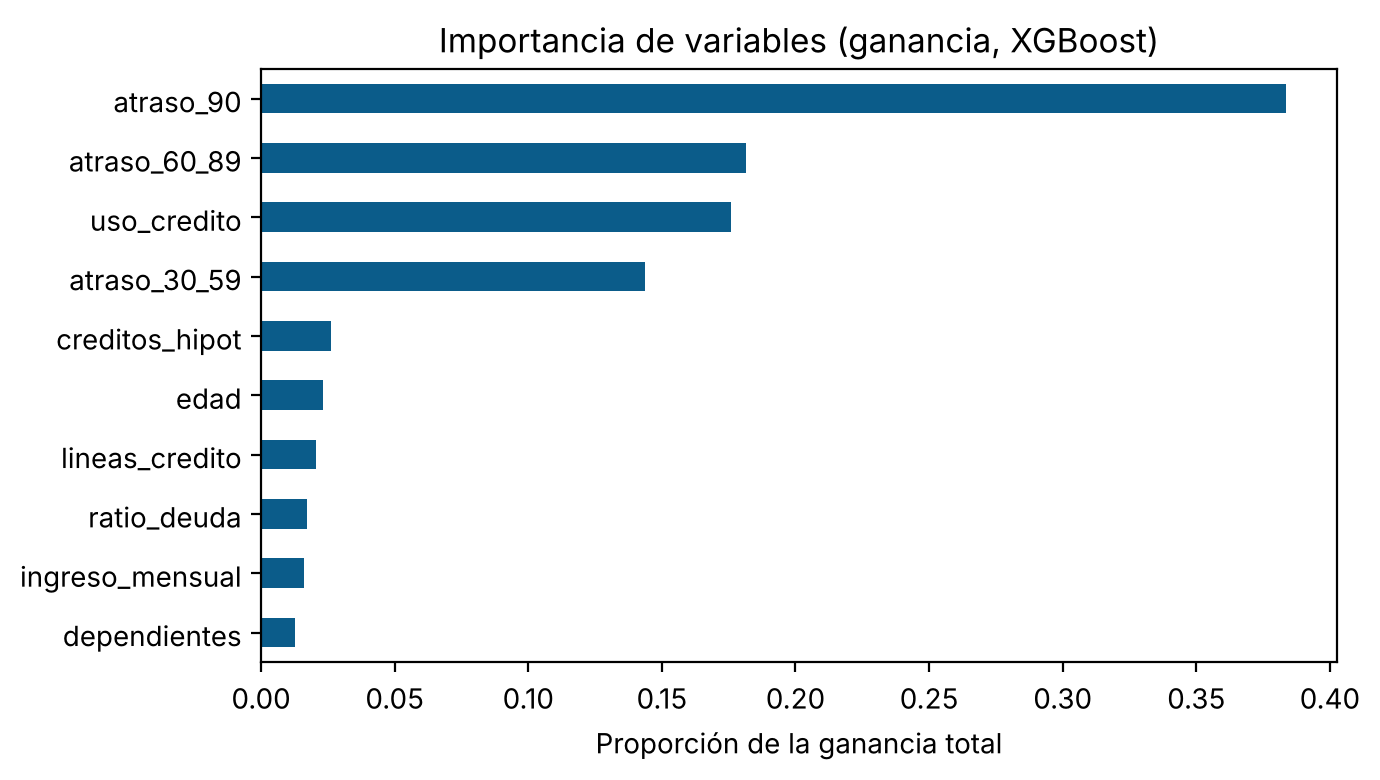

In [12]:
imp = (pd.Series(gs_xgb.best_estimator_.get_booster().get_score(importance_type="gain"))
         .reindex(X.columns).fillna(0))
imp = (imp / imp.sum()).sort_values(ascending=False)
print((imp * 100).round(1).to_frame("importancia_%"))
imp.sort_values().plot.barh(figsize=(7, 4), color="#0B5C8A")
plt.title("Importancia de variables (ganancia, XGBoost)"); plt.xlabel("Proporción de la ganancia total")
plt.tight_layout(); plt.savefig("../reports/importancia_variables.png", dpi=130); plt.show()

In [13]:
res = pd.DataFrame({
    "AUC test": [roc_auc_score(y_te, p_lr), roc_auc_score(y_te, p_xgb)],
    "KS test": [ks(y_te, p_lr), ks(y_te, p_xgb)],
    "Mora capturada en el 10% de mayor riesgo": [
        y_te[pd.Series(p, index=y_te.index).rank(ascending=False, pct=True) <= 0.10].sum() / y_te.sum()
        for p in (p_lr, p_xgb)]},
    index=["Regresión logística", "XGBoost"]).round(3)
res

,AUC test,KS test,Mora capturada en el 10% de mayor riesgo
Regresión logística,0.858,0.564,0.553
XGBoost,0.867,0.588,0.563


## 5. Resumen y conclusiones

Lo que dejó el ejercicio, sin adornos:

**1. El mejor predictor es el pasado.** Quien ya se atrasó, vuelve a atrasarse. Con cero atrasos de 90 días la mora es de 4,6%. Con un solo atraso sube a 33,7%. Con cuatro, llega a 66,1%. Entre los tres tipos de atraso explican el 71% de lo que usa XGBoost para decidir, y si sumamos el uso de las líneas de crédito llegamos al 88%.

**2. La regresión logística ya estaba en su techo.** Probé 80 combinaciones (C entre 0,0001 y 1000, L1, L2 y mezclas, con y sin pesos de clase). Desde C = 0,1 el resultado no se mueve de un AUC de 0,8555. Elegir mejor los hiperparámetros no iba a dar más.

**3. XGBoost gana, pero por poco.** AUC 0,867 contra 0,858, y KS 0,588 contra 0,564. Esa diferencia de menos de un punto significa que el modelo simple, que además se puede explicar en una reunión, hace casi todo el trabajo. Yo partiría con la regresión.

**4. Los datos venían sucios, y eso importa.** 609 filas repetidas, 20% sin ingreso, 269 clientes con códigos 96 y 98 en vez de conteos reales, y valores imposibles como un uso de crédito de 50.708. Sin limpiar eso, los números no valdrían nada.

**5. Una pista curiosa: el ratio de deuda casi no pesa.** Parece raro, pero tiene explicación. El 92% de los clientes con ratio de deuda sobre 5 no tiene ingreso registrado, así que ese ratio en realidad es un monto en pesos y no una proporción. El dato está roto justo donde más debería decir algo.

**Lo que no se puede decir.** Que algo sea "importante" para el modelo no significa que cause la mora. Se hizo una sola partición aleatoria, no por fechas, así que en un banco real habría que probar con datos de un periodo posterior. Y las cifras son de un concurso de Kaggle, no de una cartera chilena.
